<a href="https://colab.research.google.com/github/rijasattar09/introductiontocomputervision/blob/main/LABMID.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1 — Install libraries

In [10]:
!pip -q install medmnist opencv-python-headless scikit-image scikit-learn matplotlib pandas

Cell 2 — Import libraries and set your roll number

In [11]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import medmnist

from medmnist import INFO
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay
)

# Your registration number
ROLL_NUMBER = "107"

SEED = int(ROLL_NUMBER[-2:])
last_digit = int(ROLL_NUMBER[-1])

# Personal settings for roll number 107
HOG_CELL = (8, 8) if last_digit % 2 == 0 else (16, 16)
SIFT_GRID = 4 if last_digit <= 4 else 6

random.seed(SEED)
np.random.seed(SEED)

CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = {
    1: "Eosinophil",
    5: "Monocyte",
    6: "Neutrophil",
    7: "Platelet"
}

print("Roll number:", ROLL_NUMBER)
print("Random seed:", SEED)
print("HOG cell size:", HOG_CELL)
print("SIFT grid:", f"{SIFT_GRID} x {SIFT_GRID}")
print("Expected HOG features: 1764")
print("Expected SIFT features:", SIFT_GRID * SIFT_GRID * 128)

Roll number: 107
Random seed: 7
HOG cell size: (16, 16)
SIFT grid: 6 x 6
Expected HOG features: 1764
Expected SIFT features: 4608


Cell 3 — Q1: Load and prepare BloodMNIST


Training image shape: (400, 128, 128)
Training label shape: (400,)
Class counts: {'Eosinophil': 100, 'Monocyte': 100, 'Neutrophil': 100, 'Platelet': 100}

Validation image shape: (120, 128, 128)
Validation label shape: (120,)
Class counts: {'Eosinophil': 30, 'Monocyte': 30, 'Neutrophil': 30, 'Platelet': 30}

Test image shape: (120, 128, 128)
Test label shape: (120,)
Class counts: {'Eosinophil': 30, 'Monocyte': 30, 'Neutrophil': 30, 'Platelet': 30}


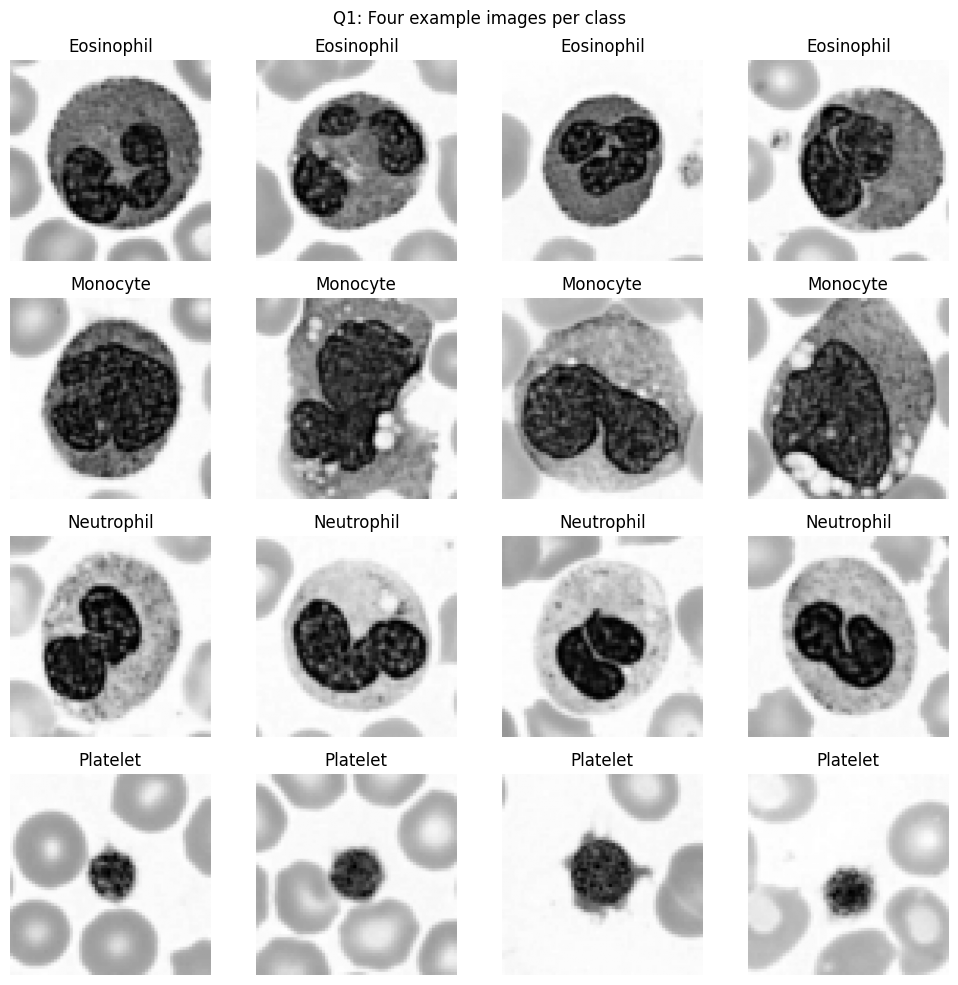

In [18]:
info = INFO["bloodmnist"]
DataClass = getattr(medmnist, info["python_class"])

train_ds = DataClass(split="train", download=True, size=64)
val_ds = DataClass(split="val", download=True, size=64)
test_ds = DataClass(split="test", download=True, size=64)

def unpack_dataset(dataset):
    images = np.asarray(dataset.imgs)
    labels = np.asarray(dataset.labels).reshape(-1).astype(int)
    return images, labels

raw_train = unpack_dataset(train_ds)
raw_val = unpack_dataset(val_ds)
raw_test = unpack_dataset(test_ds)

def prepare_split(images, labels, number_per_class):
    rng = np.random.default_rng(SEED)
    selected_images = []
    selected_labels = []

    for class_id in CLASS_IDS:
        indices = np.flatnonzero(labels == class_id)

        if len(indices) < number_per_class:
            raise ValueError(
                f"Not enough examples for class {class_id}"
            )

        chosen = rng.choice(
            indices, size=number_per_class, replace=False
        )

        for index in chosen:
            image = images[index]

            if image.ndim == 2:
                gray = image
            elif image.ndim == 3:
                gray = cv2.cvtColor(
                    image[..., :3], cv2.COLOR_RGB2GRAY
                )
            else:
                raise ValueError(f"Unexpected shape: {image.shape}")

            gray = cv2.resize(
                gray, (128, 128),
                interpolation=cv2.INTER_AREA
            )

            selected_images.append(gray.astype(np.uint8))
            selected_labels.append(class_id)

    order = rng.permutation(len(selected_labels))

    return (
        np.stack(selected_images)[order],
        np.asarray(selected_labels)[order]
    )

X_train_img, y_train = prepare_split(*raw_train, 100)
X_val_img, y_val = prepare_split(*raw_val, 30)
X_test_img, y_test = prepare_split(*raw_test, 30)

for name, X, y in [
    ("Training", X_train_img, y_train),
    ("Validation", X_val_img, y_val),
    ("Test", X_test_img, y_test)
]:
    print(f"\n{name} image shape:", X.shape)
    print(f"{name} label shape:", y.shape)

    counts = {
        CLASS_NAMES[c]: int(np.sum(y == c))
        for c in CLASS_IDS
    }
    print("Class counts:", counts)

# Display four training examples per class
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for row, class_id in enumerate(CLASS_IDS):
    indices = np.flatnonzero(y_train == class_id)[:4]

    for col, index in enumerate(indices):
        axes[row, col].imshow(X_train_img[index], cmap="gray")
        axes[row, col].set_title(CLASS_NAMES[class_id])
        axes[row, col].axis("off")

plt.suptitle("Q1: Four example images per class")
plt.tight_layout()
plt.show()

Cell 4 — Q2: HOG features and SVM

Training HOG shape: (400, 1764)
Validation HOG shape: (120, 1764)
HOG feature length: 1764

HOG hand calculation:
Cells per direction: 8
Blocks per direction: 7
Features per block: 36
Total features: 1764


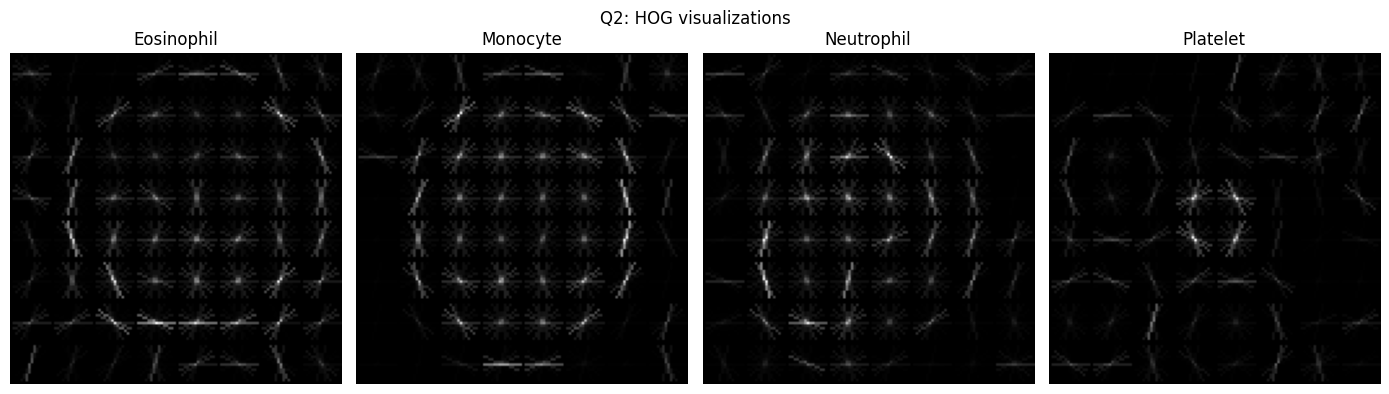

,C,Validation accuracy,Validation macro-F1
0,0.1,0.766667,0.75871
1,1.0,0.766667,0.75871
2,10.0,0.766667,0.75871


Selected C: 0.1
HOG validation accuracy: 0.7666666666666667
HOG validation macro-F1: 0.7587100213219616


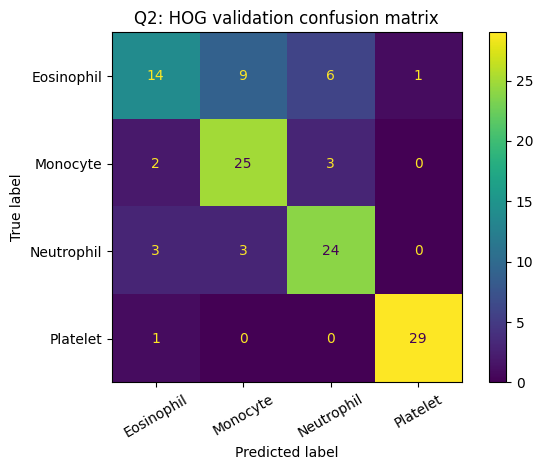

In [13]:
def extract_hog(image, visualize=False):
    return hog(
        image,
        orientations=9,
        pixels_per_cell=HOG_CELL,
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        visualize=visualize,
        feature_vector=True
    )

X_train_hog = np.stack([
    extract_hog(img) for img in X_train_img
])

X_val_hog = np.stack([
    extract_hog(img) for img in X_val_img
])

print("Training HOG shape:", X_train_hog.shape)
print("Validation HOG shape:", X_val_hog.shape)
print("HOG feature length:", X_train_hog.shape[1])

# Hand calculation for roll number 107
cells = 128 // 16
blocks = cells - 2 + 1
features_per_block = 2 * 2 * 9
hog_length = blocks * blocks * features_per_block

print("\nHOG hand calculation:")
print("Cells per direction:", cells)
print("Blocks per direction:", blocks)
print("Features per block:", features_per_block)
print("Total features:", hog_length)

# Display HOG images for the four classes
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, class_id in zip(axes, CLASS_IDS):
    index = np.flatnonzero(y_train == class_id)[0]
    _, hog_image = extract_hog(
        X_train_img[index], visualize=True
    )

    ax.imshow(hog_image, cmap="gray")
    ax.set_title(CLASS_NAMES[class_id])
    ax.axis("off")

plt.suptitle("Q2: HOG visualizations")
plt.tight_layout()
plt.show()

# Select C using validation macro-F1
def select_model(X_train, y_train, X_val, y_val):
    results = []
    models = {}

    for C in [0.1, 1, 10]:
        model = make_pipeline(
            StandardScaler(),
            LinearSVC(
                C=C, random_state=SEED, max_iter=20000
            )
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_val)

        acc = accuracy_score(y_val, predictions)
        macro_f1 = f1_score(
            y_val, predictions, average="macro"
        )

        results.append({
            "C": C,
            "Validation accuracy": acc,
            "Validation macro-F1": macro_f1
        })

        models[C] = model

    results_df = pd.DataFrame(results)
    display(results_df)

    best_row = max(
        results,
        key=lambda r: (
            r["Validation macro-F1"],
            r["Validation accuracy"]
        )
    )

    best_C = best_row["C"]
    print("Selected C:", best_C)

    return models[best_C], best_C

hog_model, hog_C = select_model(
    X_train_hog, y_train, X_val_hog, y_val
)

hog_val_pred = hog_model.predict(X_val_hog)

print("HOG validation accuracy:",
      accuracy_score(y_val, hog_val_pred))

print("HOG validation macro-F1:",
      f1_score(y_val, hog_val_pred, average="macro"))

cm = confusion_matrix(
    y_val, hog_val_pred, labels=CLASS_IDS
)

ConfusionMatrixDisplay(
    cm,
    display_labels=[CLASS_NAMES[c] for c in CLASS_IDS]
).plot(xticks_rotation=30)

plt.title("Q2: HOG validation confusion matrix")
plt.tight_layout()
plt.show()

Cell 5 — Q3: SIFT keypoints and fixed-grid descriptors

Average keypoints: 73.605
Minimum keypoints: 11
Maximum keypoints: 179
Images with zero keypoints: 0


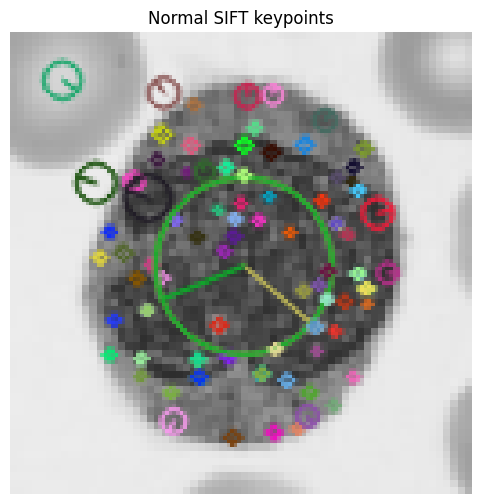

Normal SIFT produces variable-length features because different images can have different numbers of keypoints.
Training SIFT shape: (400, 4608)
Validation SIFT shape: (120, 4608)
SIFT feature length: 4608
Hand calculation: 6 x 6 = 36 grid points
Total features: 36 x 128 = 4608


,C,Validation accuracy,Validation macro-F1
0,0.1,0.708333,0.697227
1,1.0,0.700000,0.690255
2,10.0,0.700000,0.690255


Selected C: 0.1
SIFT validation accuracy: 0.7083333333333334
SIFT validation macro-F1: 0.6972273394920168


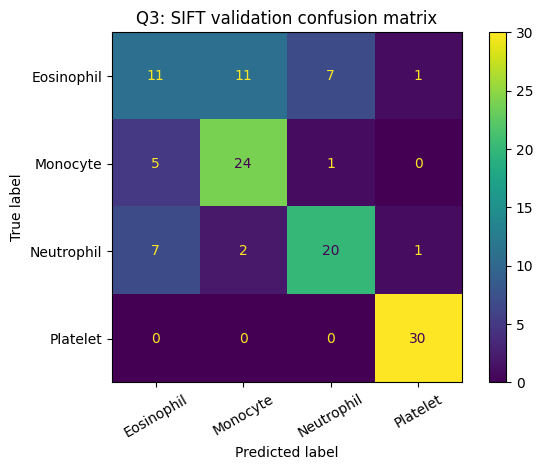

In [14]:
sift = cv2.SIFT_create()

# Normal SIFT detection statistics
keypoint_counts = []
example_keypoints = None
example_image = None

for image in X_train_img:
    keypoints, descriptors = sift.detectAndCompute(image, None)
    keypoint_counts.append(len(keypoints))

    if example_keypoints is None and len(keypoints) > 0:
        example_keypoints = keypoints
        example_image = image

keypoint_counts = np.asarray(keypoint_counts)

print("Average keypoints:",
      float(keypoint_counts.mean()))
print("Minimum keypoints:",
      int(keypoint_counts.min()))
print("Maximum keypoints:",
      int(keypoint_counts.max()))
print("Images with zero keypoints:",
      int(np.sum(keypoint_counts == 0)))

if example_keypoints is not None:
    drawn = cv2.drawKeypoints(
        example_image,
        example_keypoints,
        None,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )

    plt.figure(figsize=(6, 6))
    plt.imshow(drawn, cmap="gray")
    plt.title("Normal SIFT keypoints")
    plt.axis("off")
    plt.show()

print(
    "Normal SIFT produces variable-length features because "
    "different images can have different numbers of keypoints."
)

# Fixed-grid SIFT: 6 x 6 points, size 32
def extract_grid_sift(image):
    grid_size = SIFT_GRID

    coords = np.linspace(
        128 / (2 * grid_size),
        128 - 128 / (2 * grid_size),
        grid_size
    )

    keypoints = [
        cv2.KeyPoint(float(x), float(y), 32.0)
        for y in coords
        for x in coords
    ]

    keypoints, descriptors = sift.compute(image, keypoints)

    target_rows = grid_size * grid_size

    if descriptors is None:
        descriptors = np.zeros(
            (target_rows, 128), dtype=np.float32
        )
    elif len(descriptors) < target_rows:
        padded = np.zeros(
            (target_rows, 128), dtype=np.float32
        )
        padded[:len(descriptors)] = descriptors
        descriptors = padded
    elif len(descriptors) > target_rows:
        descriptors = descriptors[:target_rows]

    return descriptors.astype(np.float32).reshape(-1)

X_train_sift = np.stack([
    extract_grid_sift(img) for img in X_train_img
])

X_val_sift = np.stack([
    extract_grid_sift(img) for img in X_val_img
])

print("Training SIFT shape:", X_train_sift.shape)
print("Validation SIFT shape:", X_val_sift.shape)
print("SIFT feature length:", X_train_sift.shape[1])

print(
    "Hand calculation:",
    SIFT_GRID, "x", SIFT_GRID, "=",
    SIFT_GRID * SIFT_GRID, "grid points"
)
print(
    "Total features:",
    SIFT_GRID * SIFT_GRID, "x 128 =",
    SIFT_GRID * SIFT_GRID * 128
)

# Select C using validation data
sift_model, sift_C = select_model(
    X_train_sift, y_train, X_val_sift, y_val
)

sift_val_pred = sift_model.predict(X_val_sift)

print("SIFT validation accuracy:",
      accuracy_score(y_val, sift_val_pred))

print("SIFT validation macro-F1:",
      f1_score(y_val, sift_val_pred, average="macro"))

cm = confusion_matrix(
    y_val, sift_val_pred, labels=CLASS_IDS
)

ConfusionMatrixDisplay(
    cm,
    display_labels=[CLASS_NAMES[c] for c in CLASS_IDS]
).plot(xticks_rotation=30)

plt.title("Q3: SIFT validation confusion matrix")
plt.tight_layout()
plt.show()

Cell 6 — Q4: Rotation and noise tests

Q4: Test-set robustness results


,Model,Condition,Accuracy,Macro-F1
0,HOG + SVM,Clean,0.7500,0.7527
1,HOG + SVM,Rotated 20 degrees,0.6750,0.6666
2,HOG + SVM,Gaussian noise,0.3333,0.2551
3,SIFT + SVM,Clean,0.6917,0.6895
4,SIFT + SVM,Rotated 20 degrees,0.6583,0.6548
5,SIFT + SVM,Gaussian noise,0.6833,0.6792


Accuracy comparison


Condition,Clean,Gaussian noise,Rotated 20 degrees
Model,,,
HOG + SVM,0.7500,0.3333,0.6750
SIFT + SVM,0.6917,0.6833,0.6583


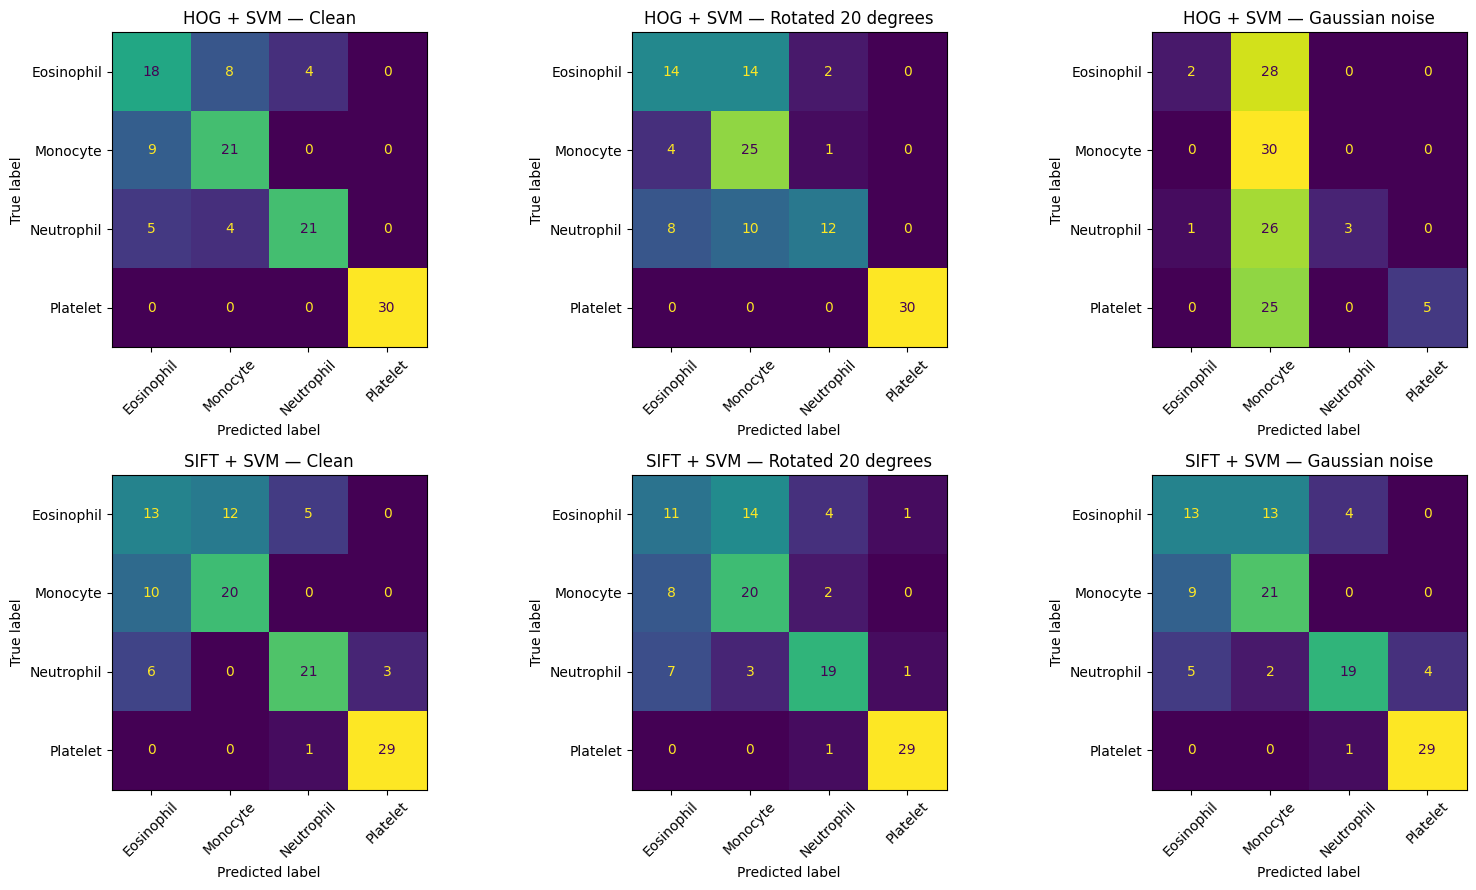


Accuracy drop under Rotated 20 degrees:
Model
HOG + SVM     0.0750
SIFT + SVM    0.0333
dtype: float64

Accuracy drop under Gaussian noise:
Model
HOG + SVM     0.4167
SIFT + SVM    0.0083
dtype: float64

Use these measured values to decide which model was more robust.


In [15]:
def rotate_image(image, angle=20):
    matrix = cv2.getRotationMatrix2D(
        (image.shape[1] / 2, image.shape[0] / 2),
        angle,
        1.0
    )

    return cv2.warpAffine(
        image,
        matrix,
        (image.shape[1], image.shape[0]),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

def add_gaussian_noise(image, sigma=0.05, seed=SEED):
    rng = np.random.default_rng(seed)

    scaled = image.astype(np.float32) / 255.0
    noise = rng.normal(0, sigma, scaled.shape)

    noisy = np.clip(scaled + noise, 0, 1)

    return np.round(noisy * 255).astype(np.uint8)

# Create changed versions of the test images
X_test_rot = np.stack([
    rotate_image(img, 20) for img in X_test_img
])

X_test_noise = np.stack([
    add_gaussian_noise(img, 0.05, SEED + i)
    for i, img in enumerate(X_test_img)
])

def evaluate_condition(images, labels, feature_type, model):
    if feature_type == "HOG":
        features = np.stack([
            extract_hog(img) for img in images
        ])
    else:
        features = np.stack([
            extract_grid_sift(img) for img in images
        ])

    predictions = model.predict(features)

    accuracy = accuracy_score(labels, predictions)
    macro_f1 = f1_score(
        labels, predictions, average="macro"
    )

    return accuracy, macro_f1, predictions

results = []
predictions = {}

for model_name, feature_type, model in [
    ("HOG + SVM", "HOG", hog_model),
    ("SIFT + SVM", "SIFT", sift_model)
]:
    for condition, images in [
        ("Clean", X_test_img),
        ("Rotated 20 degrees", X_test_rot),
        ("Gaussian noise", X_test_noise)
    ]:
        acc, mf1, pred = evaluate_condition(
            images, y_test, feature_type, model
        )

        results.append({
            "Model": model_name,
            "Condition": condition,
            "Accuracy": acc,
            "Macro-F1": mf1
        })

        predictions[(model_name, condition)] = pred

robustness_df = pd.DataFrame(results)

print("Q4: Test-set robustness results")
display(robustness_df.round(4))

print("Accuracy comparison")
display(
    robustness_df.pivot(
        index="Model",
        columns="Condition",
        values="Accuracy"
    ).round(4)
)

# Confusion matrices for all six test conditions
conditions = [
    "Clean",
    "Rotated 20 degrees",
    "Gaussian noise"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for row, model_name in enumerate(
    ["HOG + SVM", "SIFT + SVM"]
):
    for col, condition in enumerate(conditions):
        pred = predictions[(model_name, condition)]

        cm = confusion_matrix(
            y_test, pred, labels=CLASS_IDS
        )

        ConfusionMatrixDisplay(
            cm,
            display_labels=[
                CLASS_NAMES[c] for c in CLASS_IDS
            ]
        ).plot(
            ax=axes[row, col],
            colorbar=False,
            xticks_rotation=45
        )

        axes[row, col].set_title(
            f"{model_name} — {condition}"
        )

plt.tight_layout()
plt.show()

# Calculate accuracy drops
pivot = robustness_df.pivot(
    index="Model",
    columns="Condition",
    values="Accuracy"
)

for condition in ["Rotated 20 degrees", "Gaussian noise"]:
    drops = pivot["Clean"] - pivot[condition]

    print(f"\nAccuracy drop under {condition}:")
    print(drops.round(4))

print(
    "\nUse these measured values to decide which model "
    "was more robust."
)

Cell 7 — Q5: Find the most-confused classes

In [16]:
def most_confused_pair(matrix):
    matrix = matrix.copy()
    np.fill_diagonal(matrix, 0)

    row, col = np.unravel_index(
        np.argmax(matrix), matrix.shape
    )

    return (
        CLASS_NAMES[CLASS_IDS[row]],
        CLASS_NAMES[CLASS_IDS[col]],
        int(matrix[row, col])
    )

for model_name in ["HOG + SVM", "SIFT + SVM"]:
    print("\n", model_name)

    for condition in [
        "Clean",
        "Rotated 20 degrees",
        "Gaussian noise"
    ]:
        pred = predictions[(model_name, condition)]

        cm = confusion_matrix(
            y_test, pred, labels=CLASS_IDS
        )

        actual, predicted, count = most_confused_pair(cm)

        print(
            condition, "— most frequent confusion:",
            actual, "predicted as", predicted,
            "| count:", count
        )


 HOG + SVM
Clean — most frequent confusion: Monocyte predicted as Eosinophil | count: 9
Rotated 20 degrees — most frequent confusion: Eosinophil predicted as Monocyte | count: 14
Gaussian noise — most frequent confusion: Eosinophil predicted as Monocyte | count: 28

 SIFT + SVM
Clean — most frequent confusion: Eosinophil predicted as Monocyte | count: 12
Rotated 20 degrees — most frequent confusion: Eosinophil predicted as Monocyte | count: 14
Gaussian noise — most frequent confusion: Eosinophil predicted as Monocyte | count: 13


Cell 8 — Print a summary for your report

In [17]:
print("=" * 55)
print("COMPUTER VISION ASSIGNMENT — ROLL NUMBER 107")
print("=" * 55)

print("\nPersonal settings")
print("Random seed:", SEED)
print("HOG cell size:", HOG_CELL)
print("SIFT grid:", f"{SIFT_GRID} x {SIFT_GRID}")

print("\nFeature lengths")
print("HOG:", X_train_hog.shape[1])
print("SIFT:", X_train_sift.shape[1])

print("\nSelected hyperparameters")
print("HOG C:", hog_C)
print("SIFT C:", sift_C)

print("\nValidation results")
print(
    "HOG accuracy:",
    round(accuracy_score(y_val, hog_val_pred), 4)
)
print(
    "HOG macro-F1:",
    round(f1_score(y_val, hog_val_pred, average="macro"), 4)
)
print(
    "SIFT accuracy:",
    round(accuracy_score(y_val, sift_val_pred), 4)
)
print(
    "SIFT macro-F1:",
    round(f1_score(y_val, sift_val_pred, average="macro"), 4)
)

print("\nRobustness table")
display(robustness_df.round(4))

print("\nRemember to use these actual outputs in your report.")

COMPUTER VISION ASSIGNMENT — ROLL NUMBER 107

Personal settings
Random seed: 7
HOG cell size: (16, 16)
SIFT grid: 6 x 6

Feature lengths
HOG: 1764
SIFT: 4608

Selected hyperparameters
HOG C: 0.1
SIFT C: 0.1

Validation results
HOG accuracy: 0.7667
HOG macro-F1: 0.7587
SIFT accuracy: 0.7083
SIFT macro-F1: 0.6972

Robustness table


,Model,Condition,Accuracy,Macro-F1
0,HOG + SVM,Clean,0.7500,0.7527
1,HOG + SVM,Rotated 20 degrees,0.6750,0.6666
2,HOG + SVM,Gaussian noise,0.3333,0.2551
3,SIFT + SVM,Clean,0.6917,0.6895
4,SIFT + SVM,Rotated 20 degrees,0.6583,0.6548
5,SIFT + SVM,Gaussian noise,0.6833,0.6792



Remember to use these actual outputs in your report.
